[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/minchree/inventory-replenishment-agent/blob/main/notebooks/InventoryReplenishmentAgent.ipynb)

# Inventory replenishment agent

Every day, for three SKUs, this agent forecasts demand with EWMA, sets safety stock from its own forecast error, compares inventory position with an order-up-to level over the lead time plus one review day, and then orders, holds, or defers. Deferring is priced: the agent waits only when the expected shortage cost of waiting is below the holding cost it saves. It also watches its own forecast for bias and logs an ALERT when it adapts.

Run it with **Runtime > Run all**. The first cell clones [the repository](https://github.com/minchree/inventory-replenishment-agent), and everything else comes from the package in `replenish/`. After the one-page design document, the sections follow the assignment tasks T1 to T6, then the evaluation and trade-offs, the audit of the course starter notebook, the test suite, and the scaling note.

In [1]:
# Setup: works in Colab and locally, and re-running it changes nothing.
import importlib.util, os, subprocess, sys

REPO_URL = "https://github.com/minchree/inventory-replenishment-agent.git"
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    target = "/content/inventory-replenishment-agent"
    if not os.path.isdir(target):
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, target], check=True)
    os.chdir(target)
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

# Colab already has numpy, pandas, scipy and matplotlib; install only what's missing.
missing = [m for m in ("hypothesis", "pytest") if importlib.util.find_spec(m) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)

import matplotlib, numpy, pandas, scipy, hypothesis, pytest
print("Python", sys.version.split()[0], "| in Colab:", IN_COLAB, "| cwd:", os.getcwd())
for mod in (numpy, pandas, scipy, matplotlib, hypothesis, pytest):
    print(f"  {mod.__name__:<11} {mod.__version__}")

Python 3.13.14 | in Colab: False | cwd: C:\Users\minht\OneDrive\Documents\inventory-agent
  numpy       2.5.4
  pandas      3.1.0
  scipy       1.18.1
  matplotlib  3.11.2
  hypothesis  6.170.14
  pytest      9.2.0


In [2]:
# Knobs. Service levels and lead times live in data/params.csv.
ALPHA = None         # EWMA smoothing constant; None picks it per SKU on the warm-up, e.g. 0.3 fixes it
MC_SEEDS = 200       # demand paths per policy (held-out seeds 5000+); lower it for a faster run
SWEEP_SEEDS = 100    # demand paths per service level in the sweep

import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

from replenish import report
from replenish.config import WARMUP_DAYS
from replenish.data import load_dataset, read_sales
from replenish.evaluate import HEADLINE, POLICIES, diagnostics, evaluate_all, metrics_table, run_dataset

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

In [3]:
# The one-page design document: goal, inputs and outputs, guardrails, metrics, ethics and trust
display(Markdown(open("docs/DESIGN_DOCUMENT.md", encoding="utf-8").read()))

# Design document

## Goal

The agent keeps three SKUs in stock at the lowest total cost. Each day it decides, per SKU, whether to place a purchase order and how big, aiming to meet each SKU's service level while minimizing holding, stockout and ordering costs.

## Inputs and outputs

Inputs, read fresh at every daily review:
- daily demand history (`sales.csv`, aggregated per SKU per day)
- on-hand stock, open POs and backorders, starting from `inventory.csv`
- per-SKU parameters from `params.csv`: lead time, minimum order quantity, service level, unit, holding and stockout costs
- the agent's own EWMA forecast and its recent forecast errors

Outputs, per SKU per day: one action (ORDER with a quantity, HOLD, or DEFER) and a log line giving the numbers behind it. An ALERT line appears when the agent adjusts its own forecast.

## Guardrails

- Every PO is at least `min_order_qty`.
- Lead time is respected. Decisions use inventory position (on hand + on order − backorders) over L + 1 days, so stock already in transit is never ordered twice.
- Safety stock comes from `service_level` and the agent's measured forecast error.
- No single order exceeds 30 days of forecast demand unless the minimum order quantity requires it. This stops a bad data point or a broken forecast from triggering a huge PO.
- Waiting is allowed only when its expected stockout cost is below the holding cost it saves, and only if the service level it accepts stays within 2 points of the target. This is where holding cost is traded against stockout cost, one decision at a time.

## Metrics

- Stockouts: days with any unit short, and the number of units short.
- Fill rate: units served from stock on the day they were demanded, divided by units demanded.
- Total cost: holding (per unit per day on end-of-day stock) + stockout (once per unit short) + ordering (per PO; 0 here, 25 in a second run). Purchase spend is reported separately.

## Ethics and trust

A stockout breaks a promise to a customer, and excess stock ties up money that someone else has to answer for. The agent balances service reliability against cost control explicitly and shows its work. Every action is logged with the forecast, safety stock, inventory position and the cost comparison behind it, so a buyer can audit any PO, disagree with it, and see exactly which number to change. When the configured service level and the cost parameters disagree, the agent reports it (CSL*) rather than overriding a target a person set. Its tracking signal flags when its own forecast has gone wrong, so problems surface in the log instead of in empty shelves.


## T1. Load and aggregate demand per day per SKU

`data/sales.csv` is at order-line grain: a SKU-day can have up to four rows, and a day with no demand has no row at all. Aggregation sums the lines per day and SKU, then reindexes to the full calendar so missing days read as zero (`replenish/data.py`).

In [4]:
sales = read_sales("data/sales.csv")
print(f"sales.csv: {len(sales)} order lines, {sales['date'].nunique()} dates, SKUs {sorted(sales['sku'].unique())}")
print("most lines on one SKU-day:", sales.groupby(["date", "sku"]).size().max())
display(sales.head(6))

ds = load_dataset("data")
print("\nparams.csv"); display(pd.read_csv("data/params.csv"))
print("inventory.csv"); display(pd.read_csv("data/inventory.csv"))
print(f"daily demand table: {ds.demand.shape[0]} days x {ds.demand.shape[1]} SKUs; "
      f"zero-demand days per SKU: {(ds.demand == 0).sum().to_dict()}")
display(ds.demand.head(8))

sales.csv: 690 order lines, 120 dates, SKUs ['SKU-A', 'SKU-B', 'SKU-C']
most lines on one SKU-day: 4


,date,sku,qty_sold
0,2025-01-01,SKU-A,10
1,2025-01-01,SKU-A,3
2,2025-01-01,SKU-A,27
3,2025-01-01,SKU-B,6
4,2025-01-02,SKU-A,32
5,2025-01-02,SKU-A,18



params.csv


,sku,unit_cost,holding_cost_per_day,stockout_cost,lead_time_days,min_order_qty,service_level
0,SKU-A,4.000,0.020,1.500,3,60,0.950
1,SKU-B,25.000,0.100,25.000,7,120,0.980
2,SKU-C,80.000,0.400,40.000,10,24,0.980


inventory.csv


,sku,opening_stock
0,SKU-A,200
1,SKU-B,90
2,SKU-C,30


daily demand table: 120 days x 3 SKUs; zero-demand days per SKU: {'SKU-A': 0, 'SKU-B': 0, 'SKU-C': 77}


sku,SKU-A,SKU-B,SKU-C
date,,,
2025-01-01,40,6,0
2025-01-02,50,15,0
2025-01-03,48,7,0
2025-01-04,39,14,0
2025-01-05,33,10,0
2025-01-06,24,15,0
2025-01-07,33,13,0
2025-01-08,48,8,0


## T2. EWMA forecast per SKU

The first 28 days are warm-up. The EWMA level starts at the mean of the first week and runs through days 7 to 27, so every warm-up error is one step ahead. alpha is picked from 0.1 to 0.5 by the lowest one-step MSE. Each SKU is also classified by how often and how evenly it sells (Syntetos-Boylan ADI and CV²), which decides whether the reflect step can trust its tracking signal.

,chosen alpha,MSE a=0.1,MSE a=0.2,MSE a=0.3,MSE a=0.4,MSE a=0.5,demand class,ADI,CV2,reflect active
sku,,,,,,,,,,
SKU-A,0.100,111.251,114.015,116.164,116.514,114.984,smooth,1.000,0.070,True
SKU-B,0.100,7.042,7.370,7.852,8.378,8.946,smooth,1.000,0.051,True
SKU-C,0.100,3.497,3.730,4.031,4.371,4.749,intermittent,4.667,0.313,False


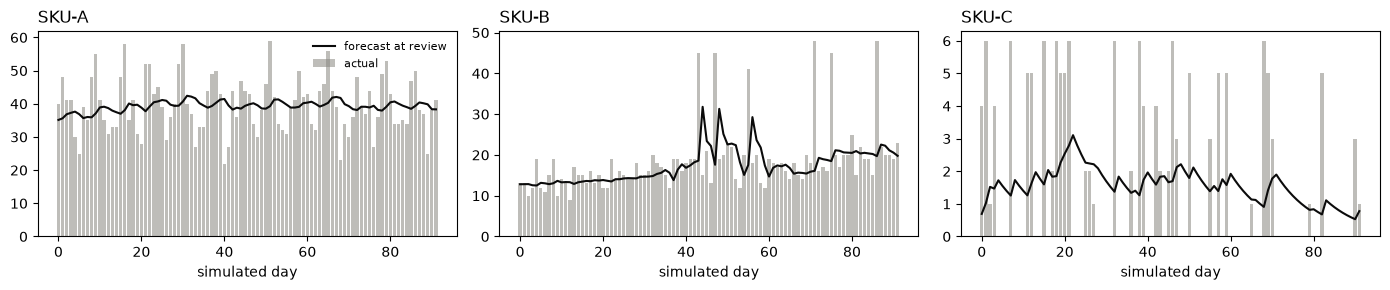

In [5]:
runs = run_dataset(ds, {**POLICIES[HEADLINE], "alpha": ALPHA})
rows = []
for sku, run in runs.items():
    agent = run.policy
    rows.append({"sku": sku, "chosen alpha": agent.memory.base_alpha,
                 **{f"MSE a={a}": m for a, m in agent.alpha_mse.items()},
                 "demand class": agent.demand_class.label, "ADI": agent.demand_class.adi,
                 "CV2": agent.demand_class.cv2, "reflect active": agent.reflect_active})
display(pd.DataFrame(rows).set_index("sku"))

fig, axes = plt.subplots(1, 3, figsize=(14, 3), sharey=False)
for ax, (sku, run) in zip(axes, runs.items()):
    ax.bar(range(len(run.decisions)), run.ledger["demand"], color="#898781", alpha=0.55, label="actual")
    ax.plot([r.forecast for r in run.decisions], color="#0b0b0b", lw=1.5, label="forecast at review")
    ax.set_title(sku, loc="left"); ax.set_xlabel("simulated day")
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

## T3. Safety stock from forecast error and service level

With L the lead time and one review day, the protection interval is P = L + 1. Then:

- sigma_1 = RMSE of the last 28 one-step forecast errors (floored at max(0.5, 10% of the forecast))
- sigma_P = sigma_1 × √P, mu_P = forecast × P
- SS = z × sigma_P with z from `service_level`, and S = mu_P + SS

The last columns check the service level against the cost parameters. CSL* = 1 − h·T/p, where T is the order-cycle length. It is report-only. The predicted fill rate is what the normal model expects at this target; the achieved fill rate is what the simulation delivered.

In [6]:
diag = diagnostics(runs)
display(pd.DataFrame(diag).T[["demand_class", "alpha", "lead_time_days", "service_level", "z", "sigma1_start",
                               "sigma_P_start", "mu_P_start", "ss_start", "S_start", "mean_order", "cycle_days",
                               "csl_star", "verdict", "predicted_fill_rate", "achieved_fill_rate"]])

,demand_class,alpha,lead_time_days,service_level,z,sigma1_start,sigma_P_start,mu_P_start,ss_start,S_start,mean_order,cycle_days,csl_star,verdict,predicted_fill_rate,achieved_fill_rate
SKU-A,smooth,0.100,3,0.950,1.645,10.548,21.095,140.551,34.698,175.249,60.167,1.517,0.980,costs favour more protection,0.994,0.999
SKU-B,smooth,0.100,7,0.980,2.054,2.654,7.506,102.520,15.415,117.934,123.200,6.699,0.973,aligned,0.999,0.960
SKU-C,intermittent,0.100,10,0.980,2.054,1.870,6.203,7.623,12.738,20.361,24.000,15.333,0.847,costs favour less protection,0.998,0.951


## T4. The daily decision: order, hold or defer

At each review the agent compares inventory position (on hand + on order − backorders) with S.

- **HOLD** when IP ≥ S.
- Below S, the order would be Q = max(MOQ, ⌈S − IP⌉). Before placing it, the agent prices waiting one day. Waiting saves h × Q of holding cost and risks dES extra units short on day t+L (from the normal loss function), at p per unit. It **DEFERs** only if waiting is cheaper and the cycle service level it accepts stays within 2 points of the target. Otherwise it **ORDERs**.
- **ALERT** lines in the T6 log come from the reflect step, when the tracking signal moves beyond 3 standard deviations of what an unbiased forecast would produce.

Three real decisions from this run, with the numbers behind them:

In [7]:
recs = [r for run in runs.values() for r in run.decisions]
examples = [next(r for r in recs if r.action == "HOLD"),
            next(r for r in recs if r.action == "ORDER" and r.moq_binds),
            next(r for r in recs if r.action == "DEFER")]
cols = ["day", "date", "sku", "action", "qty", "ip", "forecast", "sigma1", "mu_P", "ss", "S", "candidate",
        "csl_wait", "d_es", "wait_cost", "hold_saved", "floor"]
display(pd.DataFrame([{c: getattr(r, c) for c in cols} for r in examples]).set_index("day"))
for r in examples:
    print(report.log_lines(r)[-1])

,date,sku,action,qty,ip,forecast,sigma1,mu_P,ss,S,candidate,csl_wait,d_es,wait_cost,hold_saved,floor
day,,,,,,,,,,,,,,,,
28,2025-01-29,SKU-A,HOLD,0,200.000,35.138,10.548,140.551,34.698,175.249,0,NaN,NaN,NaN,NaN,NaN
29,2025-01-30,SKU-A,ORDER,60,160.000,35.624,10.357,142.496,34.072,176.567,60,0.801,2.290,3.436,1.200,0.930
33,2025-02-03,SKU-A,DEFER,0,180.000,36.883,10.005,147.532,32.913,180.446,60,0.948,0.441,0.661,1.200,0.930


d028 2025-01-29 SKU-A  HOLD     0  IP=200 >= S=175.2 (mu_P=141 + SS=34.7) | 5.7 days of cover
d029 2025-01-30 SKU-A  ORDER   60  IP=160 < S=176.6 (mu_P=142 + SS=34.1, z=1.64, sigma_P=20.7) | gap 17, MOQ 60 binds | wait: +2.29u short ($3.44) >= $1.20 holding saved -> order
d033 2025-02-03 SKU-A  DEFER    0  IP=180 < S=180.4 (mu_P=148 + SS=32.9, z=1.64, sigma_P=20.0) | gap 1, MOQ 60 binds | wait: +0.44u short ($0.66) < $1.20 holding saved, CSL_wait 0.948 >= floor 0.930 -> defer


## T5. Simulate the horizon: stockouts, fill rate and cost

POs arrive exactly L days after they are placed. Costs: holding on end-of-day stock, the stockout cost once per unit short, and the order cost per PO (0 here; the evaluation also runs 25). The charts show on hand, inventory position, S, safety stock, orders placed and received, deferrals, ALERTs and stockout days.

,demand,fill_rate,achieved_csl,stockout_days,units_short,pos,defers,alerts,capped,holding_cost,stockout_cost,order_cost,relevant_cost,purchase_spend,ending_value,avg_on_hand,avg_inventory_value,turns,forecast_mae,forecast_bias
SKU-A,"3,649.000",0.999,0.983,1.000,3.000,60.000,7.000,0.000,0.000,108.240,4.500,0.000,112.740,"14,200.000",404.000,58.826,235.304,62.030,7.108,0.376
SKU-B,"1,692.000",0.960,0.714,6.000,67.000,15.000,4.000,3.000,0.000,727.500,"1,675.000",0.000,"2,402.500","43,200.000","3,150.000",79.076,"1,976.902",21.397,4.499,1.050
SKU-C,144.000,0.951,0.833,2.000,7.000,6.000,4.000,0.000,0.000,"1,032.400",280.000,0.000,"1,312.400","11,520.000","2,400.000",28.054,"2,244.348",5.133,1.926,0.012
TOTAL,"5,485.000",0.986,0.924,9.000,77.000,81.000,15.000,3.000,0.000,"1,868.140","1,959.500",0.000,"3,827.640","68,920.000","5,954.000",165.957,"4,456.554",NaN,NaN,NaN


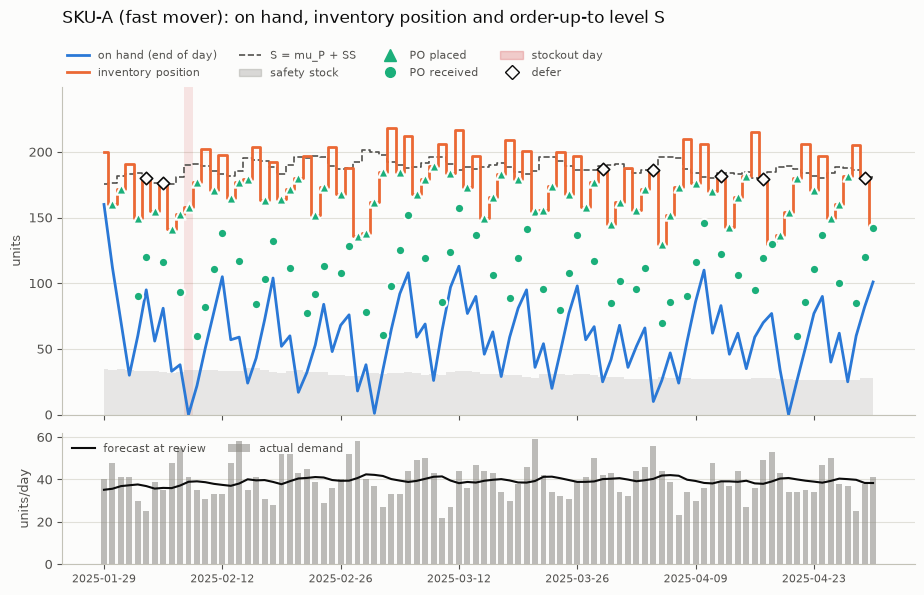

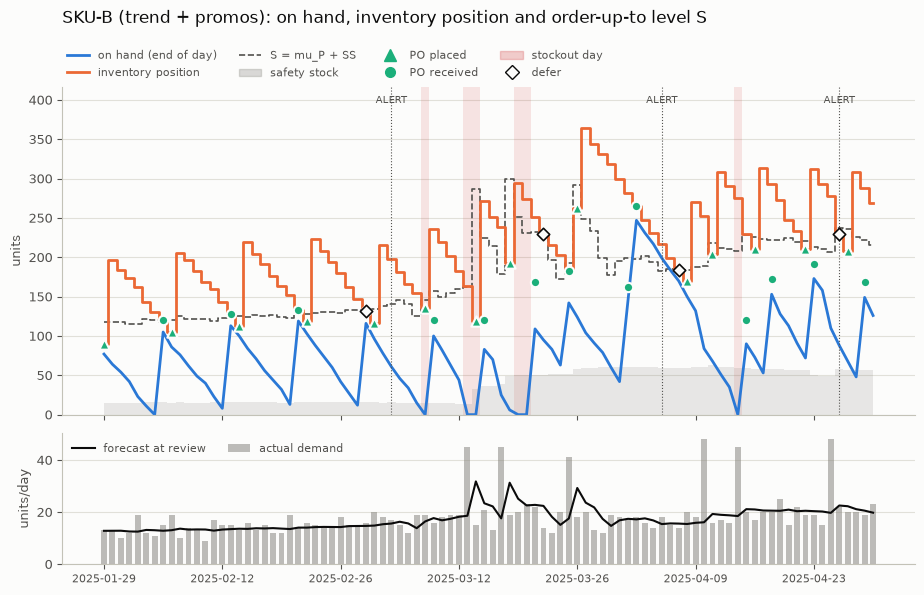

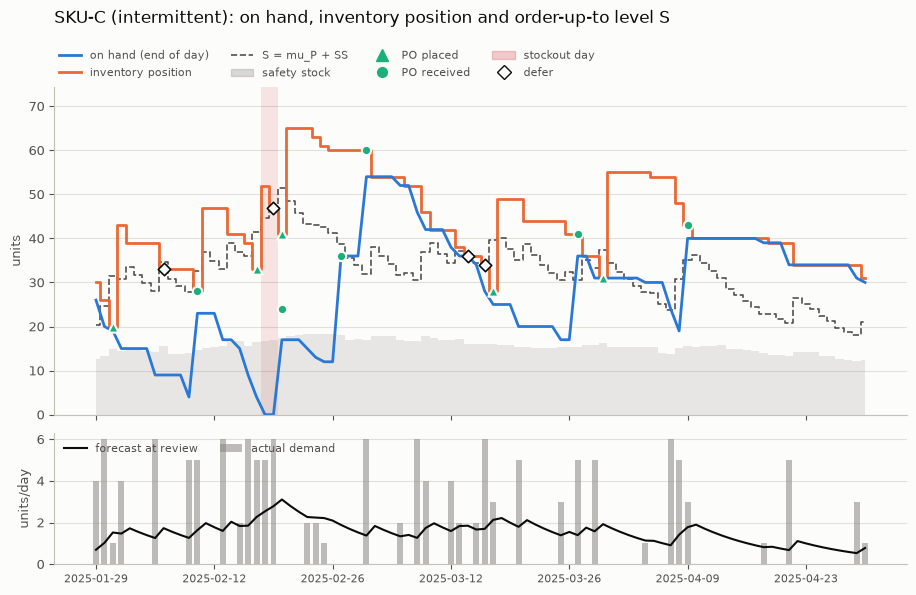

In [8]:
table = metrics_table(runs)
cols = ["demand", "fill_rate", "achieved_csl", "stockout_days", "units_short", "pos", "defers", "alerts", "capped",
        "holding_cost", "stockout_cost", "order_cost", "relevant_cost", "purchase_spend", "ending_value",
        "avg_on_hand", "avg_inventory_value", "turns", "forecast_mae", "forecast_bias"]
display(pd.DataFrame(table).T[cols])
for sku, run in runs.items():
    report.plot_inventory_story(run, close=False)
    plt.show()

## T6. Daily agent log

One line per SKU per day. Every rationale is rendered from the numbers in the decision record, so the text and the numbers always agree. The same log is saved to `outputs/agent_log.txt`, and every field is saved to `outputs/decisions.csv`.

In [9]:
log = report.write_run_outputs(runs, table, "outputs")
print("\n".join(log))
print()
print("\n".join(report.scorecard(table)))

d028 2025-01-29 SKU-A  HOLD     0  IP=200 >= S=175.2 (mu_P=141 + SS=34.7) | 5.7 days of cover
d028 2025-01-29 SKU-B  ORDER  120  IP=90 < S=117.9 (mu_P=103 + SS=15.4, z=2.05, sigma_P=7.5) | gap 28, MOQ 120 binds | wait: +10.01u short ($250.30) >= $12.00 holding saved -> order
d028 2025-01-29 SKU-C  HOLD     0  IP=30 >= S=20.4 (mu_P=7.6 + SS=12.7) | 43.3 days of cover
d029 2025-01-30 SKU-A  ORDER   60  IP=160 < S=176.6 (mu_P=142 + SS=34.1, z=1.64, sigma_P=20.7) | gap 17, MOQ 60 binds | wait: +2.29u short ($3.44) >= $1.20 holding saved -> order
d029 2025-01-30 SKU-B  HOLD     0  IP=197 >= S=117.7 (mu_P=103 + SS=15.1) | 15.4 days of cover
d029 2025-01-30 SKU-C  HOLD     0  IP=26 >= S=24.6 (mu_P=11.3 + SS=13.3) | 25.4 days of cover
d030 2025-01-31 SKU-A  ORDER   60  IP=172 < S=181.8 (mu_P=147 + SS=34.4, z=1.64, sigma_P=20.9) | gap 10, MOQ 60 binds | wait: +1.23u short ($1.85) >= $1.20 holding saved -> order
d030 2025-01-31 SKU-B  HOLD     0  IP=184 >= S=117.5 (mu_P=103 + SS=14.7) | 14.3 day

## Evaluation: baselines, ablations and 200 demand paths

One 92-day path is an anecdote, so every policy also runs on fresh demand paths from the same generator. The policies:

- P0 is the course starter's static (s,Q), run through this simulator with its metrics fixed.
- P1 uses a naive forecast.
- P2 is the textbook EWMA agent, with no defer and no reflect.
- P3 is the full agent.
- P4 knows the future and carries no safety stock. It's a reference point, not an optimum.

Two ablations switch off defer and reflect one at a time. The design was settled on dev seeds 1000-1199; these results use held-out seeds 5000 and up.

single path (committed CSVs) ...
Monte Carlo over 200 demand seeds ...


service-level sweep over 100 seeds ...


figures ...


wrote outputs
Committed CSVs, all SKUs:


,fill_rate,stockout_days,units_short,holding_cost,stockout_cost,relevant_cost,pos
policy,,,,,,,
"P0 starter (s,Q)",0.810,67,"1,043.000",797.220,"15,308.500","16,105.720",81
P1 naive agent,0.982,9,100.000,"3,787.480",855.000,"4,642.480",75
P2 EWMA textbook,0.990,4,53.000,"1,906.320","1,325.000","3,231.320",82
P3 full agent,0.986,9,77.000,"1,868.140","1,959.500","3,827.640",81
P4 clairvoyant,1.000,0,0.000,"1,057.280",0.000,"1,057.280",77
P3 without defer,0.990,4,53.000,"2,007.120","1,325.000","3,332.120",81
P3 without reflect,0.988,8,67.000,"1,802.340","1,709.500","3,511.840",82


200 demand paths, all SKUs (mean, 5th and 95th percentile):


,sku,fill_rate_mean,fill_rate_p5,fill_rate_p95,stockout_days_mean,stockout_days_p5,stockout_days_p95,relevant_cost_mean,relevant_cost_p5,relevant_cost_p95
policy,,,,,,,,,,
"P0 starter (s,Q)",TOTAL,0.842,0.792,0.882,54.625,45.000,66.000,"14,046.475","11,028.542","17,432.612"
P1 naive agent,TOTAL,0.978,0.962,0.990,8.555,5.000,12.000,"4,512.137","3,711.575","5,415.467"
P2 EWMA textbook,TOTAL,0.990,0.980,0.997,5.135,2.000,9.000,"3,091.874","2,208.493","4,314.396"
P3 full agent,TOTAL,0.987,0.977,0.996,6.270,3.000,10.000,"3,221.508","2,175.326","4,528.087"
P4 clairvoyant,TOTAL,0.997,0.991,1.000,1.540,0.000,3.000,"1,529.578","1,090.701","2,264.391"
P3 without defer,TOTAL,0.990,0.980,0.997,5.135,2.000,9.000,"3,137.228","2,194.826","4,332.478"
P3 without reflect,TOTAL,0.988,0.977,0.996,6.125,3.000,10.000,"3,132.851","2,125.886","4,337.502"


Paired comparison of relevant cost on the same paths:


,a,b,metric,mean_delta,p5,p95,share_a_lower,seeds
0,P3 full agent,P2 EWMA textbook,relevant_cost,129.634,-311.840,870.450,0.475,200
1,P3 full agent,P3 without defer,relevant_cost,84.280,-218.953,646.714,0.570,200
2,P3 full agent,P3 without reflect,relevant_cost,88.658,-428.035,650.495,0.330,200
3,P3 full agent,"P0 starter (s,Q)",relevant_cost,"-10,824.966","-14,364.725","-7,865.709",1.000,200
4,P3 full agent,P1 naive agent,relevant_cost,"-1,290.629","-2,040.666",-95.624,0.965,200


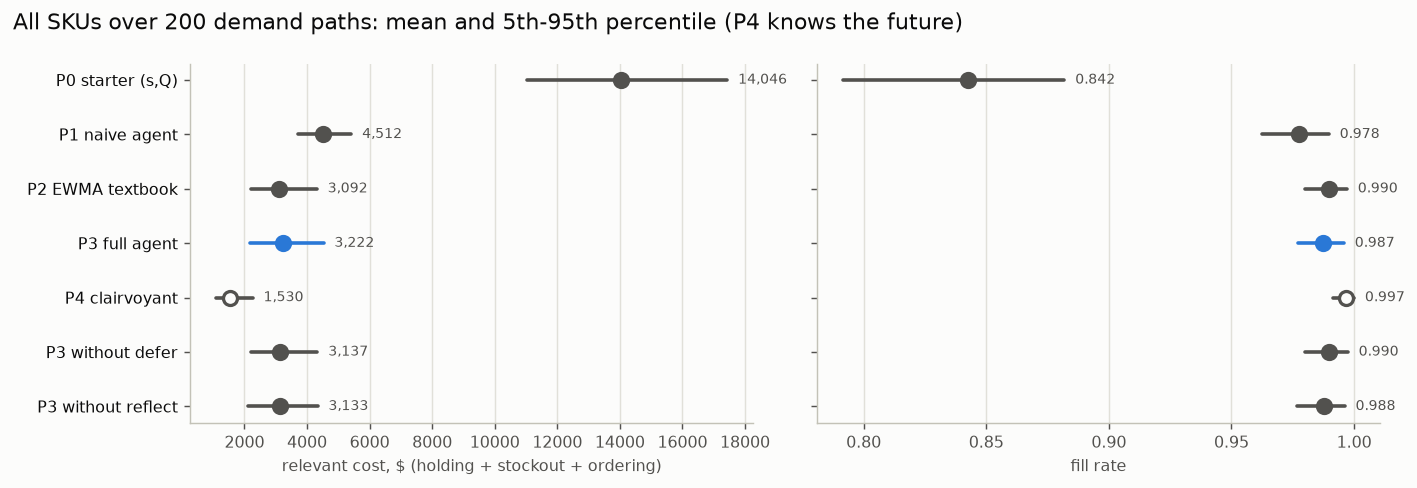

In [10]:
res = evaluate_all(ds, "outputs", mc_seeds=MC_SEEDS, sweep_seeds=SWEEP_SEEDS)
comp = res["comparison"]
print("Committed CSVs, all SKUs:")
display(comp[comp.sku == "TOTAL"].set_index("policy")[["fill_rate", "stockout_days", "units_short", "holding_cost",
                                                     "stockout_cost", "relevant_cost", "pos"]])
print(f"{MC_SEEDS} demand paths, all SKUs (mean, 5th and 95th percentile):")
display(res["summary"][res["summary"].sku == "TOTAL"].set_index("policy"))
print("Paired comparison of relevant cost on the same paths:")
display(pd.DataFrame(res["deltas"]))
display(Image("outputs/figures/policy_comparison.png"))

In [11]:
# Where each signature feature pays and where it costs, per SKU (P3 minus the ablation, same paths)
mc = res["mc"]
def per_sku(other):
    a = mc[mc.policy == HEADLINE].set_index(["seed", "sku"]).relevant_cost
    b = mc[mc.policy == other].set_index(["seed", "sku"]).relevant_cost
    d = (a - b).groupby("sku")
    return pd.DataFrame({"mean $ difference": d.mean(), "share of paths P3 cheaper": d.apply(lambda s: (s < 0).mean())})
for other in ("P3 without defer", "P3 without reflect", "P2 EWMA textbook"):
    print(f"P3 full agent minus {other}:")
    display(per_sku(other))

P3 full agent minus P3 without defer:


,mean $ difference,share of paths P3 cheaper
sku,,
SKU-A,1.289,0.680
SKU-B,139.319,0.535
SKU-C,-56.328,0.815
TOTAL,84.280,0.570


P3 full agent minus P3 without reflect:


,mean $ difference,share of paths P3 cheaper
sku,,
SKU-A,0.000,0.000
SKU-B,88.657,0.330
SKU-C,0.000,0.000
TOTAL,88.658,0.330


P3 full agent minus P2 EWMA textbook:


,mean $ difference,share of paths P3 cheaper
sku,,
SKU-A,1.289,0.680
SKU-B,184.673,0.305
SKU-C,-56.328,0.815
TOTAL,129.634,0.475


### Service-level sweep

The full agent is run at service levels from 0.80 to 0.995, plus each SKU's CSL*, and mean cost is plotted against fill rate. If CSL* is a good guide, the cheapest level in the sweep should sit near it.

       configured  CSL*  cheapest in sweep
SKU-A       0.950 0.980              0.980
SKU-B       0.980 0.973              0.995
SKU-C       0.980 0.847              0.800


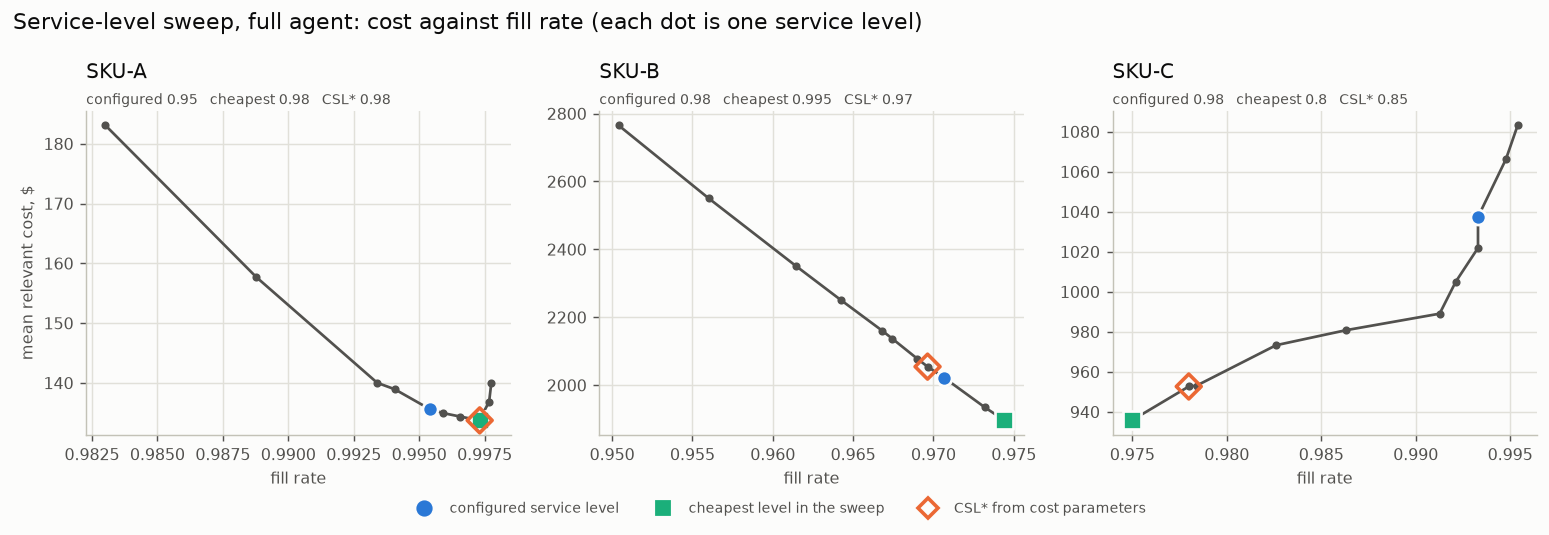

In [12]:
sweep = res["sweep"]
best = sweep.loc[sweep.groupby("sku").relevant_cost.idxmin()].set_index("sku")
print(pd.DataFrame({"configured": {s: d["service_level"] for s, d in res["diagnostics"].items()},
                    "CSL*": {s: d["csl_star"] for s, d in res["diagnostics"].items()},
                    "cheapest in sweep": best.service_level}).to_string())
display(Image("outputs/figures/sl_frontier.png"))

In [13]:
# Trade-off reflection: inventory vs service
display(Markdown(open("docs/TRADE_OFFS.md", encoding="utf-8").read()))

# Inventory vs service: the trade-offs

More safety stock buys fewer stockouts with more holding cost, and where the balance sits depends on what a stockout costs compared with a day of holding. The service-level sweep (`outputs/sl_sweep.csv`, 100 held-out demand paths) shows all three cases.

SKU-A is cheap to hold and its stockout cost is comparatively high, so raising its service level from the configured 0.95 to 0.98 lowers mean cost from $135.64 to $133.93. The configured target is too low for its own economics, and CSL* (0.98) says so.

SKU-C is the opposite. An $80 unit with a 24-unit minimum order sits on the shelf for about two weeks. Holding it at a 0.98 service level costs $1,037 per path, against $936 at 0.80, and the extra spend buys 1.8 points of fill rate. That can still be the right call if missing an order for this item costs more than the $40 stockout parameter captures, for example by losing a customer. That is a business decision, and the agent leaves it with the buyer.

SKU-B has promo days that a normal model doesn't expect, so even at 0.98 its fill rate is about 0.97. Cost keeps falling all the way to 0.995. The defer rule shows the same tension day to day: on SKU-C, waiting saves holding cost and rarely hurts, while on SKU-B a one-day wait, made while the forecast was running behind the rising trend, produced a 4-unit stockout that cost about eight times the holding it saved.

The cheapest policy isn't automatically the right one. A stockout on a promoted item damages trust in a way a per-unit penalty doesn't measure. That's why the agent reports where cost and service disagree instead of quietly optimizing one of them.


## Audit of the course starter notebook

The starter was ported line for line to `baselines/starter_port.py`. Each suspected defect became a property test that runs on both the port (expected to fail, strict xfail) and this agent (must pass). All seven were confirmed; details are in `docs/STARTER_AUDIT.md`. The table below re-runs the starter's own data and parameters, fixing one thing at a time.

In [14]:
from baselines.audit import starter_before_after
display(starter_before_after().set_index("version"))

,fill_rate,stockout_days,holding_cost,order_cost,stockout_cost,total_cost
version,,,,,,
Starter as shipped (its own sim and KPIs),0.948,NaN,"9,301.287","11,000.000","1,858.543","22,159.830"
"Same policy, metrics fixed (H5 fill rate, H6 stockout charged once)",0.945,32.000,"9,301.287","11,000.000","1,550.748","21,852.035"
+ protection interval L+1 (H7),0.979,15.000,"10,672.064","11,000.000",582.113,"22,254.176"
"Our textbook agent P2: EWMA, sigma from forecast error (H1-H4, H7), MOQ = EOQ",0.996,3.000,"11,752.200","11,000.000",102.238,"22,854.438"
"Our full agent P3: + defer + calibrated reflect, MOQ = EOQ",0.996,3.000,"11,623.800","11,000.000",102.238,"22,726.038"


## Tests

The suite covers the hand-worked 6-day trace in `docs/DESIGN.md`, the worked examples from the brief, data loading, and the forecast maths. Hypothesis checks six invariants on 200 random scenarios each: the stock ledger balances, POs arrive exactly L days later, MOQ is respected, costs recompute from the ledger, no decision sees future demand, and the clairvoyant policy never stocks out once its first order can land. The `xfail` lines are the starter defects, failing as expected.

In [15]:
out = subprocess.run([sys.executable, "-m", "pytest", "-q", "-rx", "--color=no", "-p", "no:cacheprovider"],
                     capture_output=True, text=True)
print(out.stdout[-6000:])
print("pytest exit code:", out.returncode)

.......................................x.x.x.x.x.x.x                     [100%]
=========================== short test summary info ===========================
XFAIL tests/test_starter_audit.py::test_h1_the_forecast_for_day_t_does_not_see_day_t[starter] - H1: ma7 = rolling(7).mean() includes the same day's demand
XFAIL tests/test_starter_audit.py::test_h2_todays_decision_ignores_demand_after_today[starter] - H2: tool_forecast averages predictions for days i..i+L-1, built from later actuals
XFAIL tests/test_starter_audit.py::test_h3_a_forecastable_series_gets_less_safety_stock[starter] - H3: safety stock uses the std of raw demand, not forecast error
XFAIL tests/test_starter_audit.py::test_h4_a_much_higher_forecast_triggers_an_order[starter] - H4: decide() triggers on the static global ROP; the forecast only sizes the order
XFAIL tests/test_starter_audit.py::test_h5_fill_rate_is_units_filled_over_units_demanded[starter] - H5: kpis() divides by the backlog level summed over days
XFAIL te

In [16]:
# Scaling note: deployment, monitoring, reliability, cost controls
display(Markdown(open("docs/SCALING.md", encoding="utf-8").read()))

# Scaling note

**Deployment.** Package the `replenish` module in a container and run it once a day as a scheduled job, for example Cloud Scheduler triggering a Cloud Run job or a scheduled ECS task, after the nightly sales export lands. SKUs are independent, so large catalogs shard by SKU across parallel tasks. For the first months the job writes recommended POs for a buyer to approve, not orders straight to the ERP.

**Monitoring.** Ship the daily log and `decisions.csv` to central logging. Alert when a SKU's rolling 7-day fill rate falls more than 2 points below its target, when the tracking signal raises an ALERT (already in the log), and when forecast MAE drifts above its 28-day baseline. A daily dashboard shows stockouts, fill rate and cost per SKU.

**Reliability.** Key each run by date and SKU so a retried job can't place a PO twice. Retry ERP and data-feed calls with exponential backoff. Validate inputs before deciding: `SkuParams` already rejects impossible lead times, MOQs and service levels. A missing day in the sales feed must stop the decision for that SKU and raise an alert. Today the code reads a missing day as zero demand, which is right for the order-line CSV but wrong for a feed outage.

**Cost controls.** The 30-days-of-cover cap on any single PO is already in `plan_order`. `avg_inventory_value` tracks the working capital tied up in stock. In production, add a budget ceiling per category that blocks new POs when stock value would exceed it, and send those blocks to a buyer.
